# Step 5: Baseline classifiers

**Goal:** get the first real numbers. Five classical models, each inside the scaler pipeline from Step 4, run on all
three protocols. These are the reference every later improvement (PCA/LDA, boosting, tuning, stacking) must beat.

- **Models:** kNN (k=5), SVM (RBF, C=1), Decision Tree, Random Forest (100 trees), Naive Bayes.
- **Settings are the library defaults, fixed in advance. Nothing is tuned here** (tuning is Step 8), and the test
  batches are never used to choose anything.
- **Headline:** protocol A (train batches 1-3, test batches 4-10). B and C are supporting analysis.
- Trained protocol-A models are saved to `results/models/` for the dashboard demo later.

In [1]:
import os
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import data_loader as dl
from src import evaluation as ev
from src import models

pd.set_option("display.width", 160)
df = dl.remove_toluene(dl.load_all())
baselines = models.get_baselines()
NAMES = models.BASELINE_NAMES
COLORS = dict(zip(NAMES, sns.color_palette("tab10", 5)))
Path("../results/models").mkdir(parents=True, exist_ok=True)
print("Rows:", len(df), "| models:", NAMES)

Rows: 12077 | models: ['kNN', 'SVM', 'Decision Tree', 'Random Forest', 'Naive Bayes']


## 1. Run all models on all three protocols

In [2]:
all_metrics, fit_seconds = [], {}
for name, make in baselines.items():
    for p in "ABC":
        t0 = time.perf_counter()
        if p == "A":
            split = ev.get_splits("A")[0]
            m, preds, fitted = ev.evaluate_split(make, df, split, return_model=True)
            joblib.dump(fitted, f"../results/models/baseline_{name.replace(' ', '_').lower()}_protocolA.joblib")
            fit_seconds[name] = time.perf_counter() - t0
        else:
            m, preds = ev.run_protocol(make, df, p)
        m.insert(0, "model", name)
        all_metrics.append(m)
    print(f"{name:14s} done")

metrics = pd.concat(all_metrics, ignore_index=True)
metrics.to_csv("../results/step5_baseline_metrics.csv", index=False)
print(len(metrics), "result rows saved")

kNN            done


SVM            done


Decision Tree  done


Random Forest  done


Naive Bayes    done
130 result rows saved


## 2. Protocol A (headline): train on batches 1-3, test on batches 4-10

In [3]:
A = metrics[metrics["protocol"] == "A"]
pooled = A[A["test_batch"] == "pooled"].set_index("model").loc[NAMES]
per_batch = A[A["test_batch"] != "pooled"].copy()
per_batch["test_batch"] = per_batch["test_batch"].astype(int)

table_A = pd.DataFrame({
    "pooled accuracy": pooled["accuracy"],
    "pooled macro-F1": pooled["macro_f1"],
    "mean per-batch accuracy": per_batch.groupby("model")["accuracy"].mean(),
    "worst batch accuracy": per_batch.groupby("model")["accuracy"].min(),
    "fit+predict seconds": pd.Series(fit_seconds),
}).loc[NAMES].sort_values("pooled accuracy", ascending=False)
table_A.round(3)

,pooled accuracy,pooled macro-F1,mean per-batch accuracy,worst batch accuracy,fit+predict seconds
SVM,0.727,0.740,0.795,0.517,1.551
kNN,0.696,0.707,0.702,0.518,0.619
Random Forest,0.647,0.617,0.671,0.348,0.836
Naive Bayes,0.565,0.567,0.586,0.185,0.122
Decision Tree,0.497,0.466,0.571,0.355,0.313


In [4]:
table_A.round(4).to_csv("../results/step5_protocolA_summary.csv")
acc_by_batch = per_batch.pivot(index="test_batch", columns="model", values="accuracy")[NAMES]
f1_by_batch = per_batch.pivot(index="test_batch", columns="model", values="macro_f1")[NAMES]
print("Per-batch accuracy")
acc_by_batch.round(3)

Per-batch accuracy


model,kNN,SVM,Decision Tree,Random Forest,Naive Bayes
test_batch,,,,,
4,0.733,0.876,0.820,0.870,0.807
5,0.756,0.954,0.751,0.756,0.853
6,0.789,0.871,0.718,0.911,0.765
7,0.737,0.812,0.481,0.703,0.645
8,0.518,0.587,0.377,0.348,0.185
9,0.783,0.946,0.493,0.678,0.472
10,0.598,0.517,0.355,0.435,0.376


In [5]:
print("Per-batch macro-F1")
f1_by_batch.round(3)

Per-batch macro-F1


model,kNN,SVM,Decision Tree,Random Forest,Naive Bayes
test_batch,,,,,
4,0.766,0.905,0.841,0.830,0.808
5,0.796,0.955,0.705,0.725,0.847
6,0.727,0.789,0.646,0.866,0.641
7,0.751,0.825,0.462,0.697,0.656
8,0.602,0.666,0.320,0.314,0.125
9,0.729,0.945,0.377,0.621,0.309
10,0.615,0.537,0.340,0.418,0.346


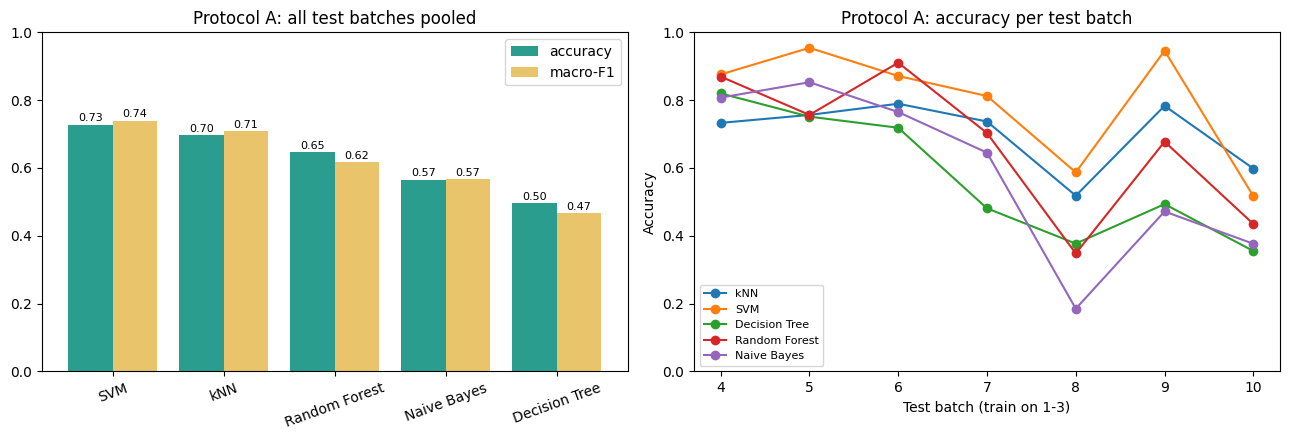

In [6]:
order = table_A.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(order))
axes[0].bar(x - 0.2, table_A["pooled accuracy"], 0.4, label="accuracy", color="#2a9d8f")
axes[0].bar(x + 0.2, table_A["pooled macro-F1"], 0.4, label="macro-F1", color="#e9c46a")
for i, n in enumerate(order):
    axes[0].text(i - 0.2, table_A.loc[n, "pooled accuracy"] + 0.01, f"{table_A.loc[n, 'pooled accuracy']:.2f}", ha="center", fontsize=8)
    axes[0].text(i + 0.2, table_A.loc[n, "pooled macro-F1"] + 0.01, f"{table_A.loc[n, 'pooled macro-F1']:.2f}", ha="center", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(order, rotation=20)
axes[0].set_ylim(0, 1); axes[0].set_title("Protocol A: all test batches pooled")
axes[0].legend(loc="upper right")

for n in NAMES:
    axes[1].plot(acc_by_batch.index, acc_by_batch[n], marker="o", color=COLORS[n], label=n)
axes[1].set_xlabel("Test batch (train on 1-3)"); axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1); axes[1].set_title("Protocol A: accuracy per test batch")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../results/step5_protocolA.png", dpi=150)
plt.show()

**What to notice (protocol A, untuned models):**
- **SVM is best:** 72.7% pooled accuracy and 74.0% macro-F1. kNN is second (69.6% / 70.7%), then Random Forest
  (64.7% / 61.7%), Naive Bayes (56.5% / 56.7%) and Decision Tree (49.7% / 46.6%).
- **Every model gets worse on later batches.** The lowest batch is 8 for kNN (51.8%), Random Forest (34.8%) and
  Naive Bayes (18.5%), and 10 for SVM (51.7%) and Decision Tree (35.5%), with batch 8 close behind for those two
  (58.7% and 37.7%). The decline is **not smooth**: batch 9 rebounds (SVM 94.6%).
- **Pooled vs per-batch:** SVM's average over batches is 79.5%, higher than its pooled 72.7%, because batches 7 and 10
  hold 68% of all test samples and SVM is weaker on batch 10. Pooled numbers are dominated by the big batches.
- **Ranking is not the same in every batch:** kNN beats SVM on batch 10, and Random Forest beats SVM on batch 6.
- **A single Decision Tree is weakest;** Random Forest, which averages many trees, does clearly better.

Batches 5 and 8 are small (197 and 276 samples), so differences between models there are not reliable.
Confidence intervals (Step 10) will show which gaps are real. Nothing was tuned yet, so these are starting points.

## 3. Protocols B and C (supporting analysis)

In [7]:
def per_batch_table(proto):
    m = metrics[(metrics["protocol"] == proto)].copy()
    m["test_batch"] = m["test_batch"].astype(int)
    return m.pivot(index="test_batch", columns="model", values="accuracy")[NAMES]

B, C = per_batch_table("B"), per_batch_table("C")
summary_BC = pd.DataFrame({
    "B mean accuracy": B.mean(), "B worst": B.min(),
    "C mean accuracy": C.mean(), "C worst": C.min(),
}).loc[NAMES]
summary_BC.round(3).to_csv("../results/step5_protocolBC_summary.csv")
summary_BC.round(3)

,B mean accuracy,B worst,C mean accuracy,C worst
model,,,,
kNN,0.407,0.149,0.826,0.696
SVM,0.430,0.228,0.872,0.686
Decision Tree,0.551,0.246,0.743,0.462
Random Forest,0.506,0.228,0.848,0.653
Naive Bayes,0.528,0.167,0.558,0.116


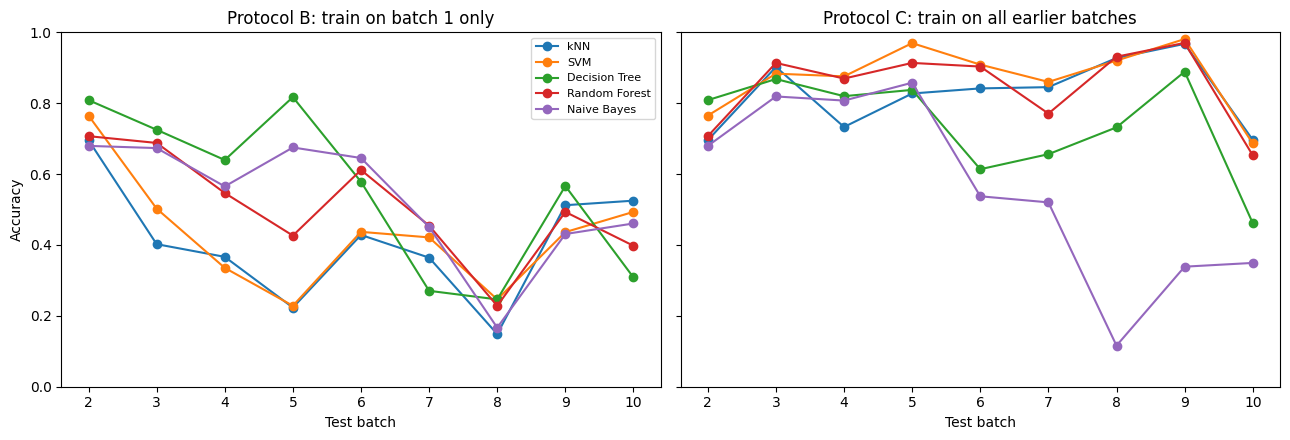

Protocol B accuracy per test batch
model         kNN    SVM  Decision Tree  Random Forest  Naive Bayes
test_batch                                                         
2           0.696  0.765          0.809          0.707        0.680
3           0.402  0.503          0.725          0.688        0.673
4           0.366  0.335          0.640          0.547        0.565
5           0.223  0.228          0.817          0.426        0.675
6           0.428  0.437          0.578          0.612        0.645
7           0.364  0.421          0.271          0.455        0.451
8           0.149  0.246          0.246          0.228        0.167
9           0.512  0.436          0.566          0.493        0.431
10          0.525  0.493          0.308          0.398        0.461

Protocol C accuracy per test batch
model         kNN    SVM  Decision Tree  Random Forest  Naive Bayes
test_batch                                                         
2           0.696  0.765          0.809      

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tab, title in [(axes[0], B, "Protocol B: train on batch 1 only"),
                       (axes[1], C, "Protocol C: train on all earlier batches")]:
    for n in NAMES:
        ax.plot(tab.index, tab[n], marker="o", color=COLORS[n], label=n)
    ax.set_title(title); ax.set_xlabel("Test batch"); ax.set_ylim(0, 1)
axes[0].set_ylabel("Accuracy"); axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("../results/step5_protocolBC.png", dpi=150)
plt.show()
print("Protocol B accuracy per test batch"); print(B.round(3))
print("\nProtocol C accuracy per test batch"); print(C.round(3))

**What to notice:**
- **Protocol B (train on batch 1 only, 371 samples):** accuracy is much lower and very uneven, with an average
  of 41-55% depending on the model, and a worst case of 14.9% (kNN on batch 8). Batch 8 is the worst or near-worst for
  every model (15-25%). The ranking differs from protocol A: here the Decision Tree has the best average (55.1%)
  while kNN and SVM are lowest (40.7% and 43.0%). With such a small training set these differences are noisy, so
  we do not read much into the ranking.
- **Protocol C (retrain on all earlier batches each time):** accuracy is much higher: SVM averages 87.2%, Random
  Forest 84.8%, kNN 82.6%, Decision Tree 74.3% and Naive Bayes 55.8%. Naive Bayes collapses on batches 8-10 (12-35%).
  Even here batch 10 is still the hardest for most models (SVM 68.6%, kNN 69.7%).

**Important:** protocol C uses labelled data from the batches just before the test batch, so it is not comparable
to protocol A. It shows how much recent labelled data helps, and is the reason the plan keeps A as the headline.

## 4. Saved models

In [9]:
for f in sorted(Path("../results/models").glob("*.joblib")):
    print(f"{f.name:48s} {f.stat().st_size / 1e6:6.2f} MB")

baseline_decision_tree_protocolA.joblib            0.01 MB
baseline_knn_protocolA.joblib                      3.30 MB
baseline_naive_bayes_protocolA.joblib              0.01 MB
baseline_random_forest_protocolA.joblib            1.17 MB
baseline_svm_protocolA.joblib                      0.56 MB


## Summary of Step 5
- First real numbers, protocol A (pooled accuracy): SVM 72.7%, kNN 69.6%, Random Forest 64.7%, Naive Bayes 56.5%,
  Decision Tree 49.7%. These are the baselines for everything that follows.
- Accuracy falls on later batches for every model, unevenly: batches 8 and 10 are the hardest.
- With only batch 1 for training (protocol B) accuracy is much lower; with all earlier batches (protocol C) it is much
  higher, which shows how much recent labelled data helps.
- The kNN result matches the Step 4 sanity check (69.6%), which confirms the bench is consistent.
- All models use default settings, no tuning, and nothing was chosen using test batches.
- Limits: single run with fixed seeds (repeats come in Step 12), no confidence intervals yet (Step 10), small batches
  are noisy.